In [1]:
import sys; sys.path.append("..")
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, recall_score, precision_score, confusion_matrix, classification_report
from src.model import sigmoid, cost, fit, predict_proba

df = pd.read_csv("../data/diabetes_binary_health_indicators_BRFSS2015.csv")
print(df.shape, "diabetic share:", df.Diabetes_binary.mean())

# Dropped on purpose: Income and Education (US-specific scales),
# CholCheck, AnyHealthcare, NoDocbcCost (about the US healthcare system)
FEATURES = ["HighBP", "HighChol", "BMI", "Smoker", "Stroke", "HeartDiseaseorAttack",
            "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "GenHlth",
            "MentHlth", "PhysHlth", "DiffWalk", "Sex", "Age"]

df["BMI"] = df["BMI"].clip(12, 60)
X = df[FEATURES].values.astype(float)
y = df["Diabetes_binary"].values.astype(float)

X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_va, y_tr, y_va = train_test_split(X_tv, y_tv, test_size=0.25, stratify=y_tv, random_state=42)
# 60% train / 20% validation / 20% test (test is used once, at the end)

mu, sd = X_tr.mean(axis=0), X_tr.std(axis=0)      # from TRAIN only
scale = lambda A: (A - mu) / sd
Xtr, Xva = scale(X_tr), scale(X_va)

(253680, 22) diabetic share: 0.13933301797540207


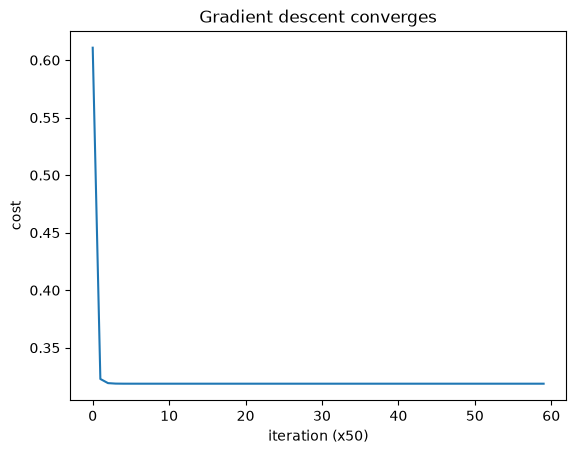

In [2]:
w, b, hist = fit(Xtr, y_tr, lam=1.0, alpha=0.5, iters=3000)
plt.plot(hist); plt.xlabel("iteration (x50)"); plt.ylabel("cost"); plt.title("Gradient descent converges")
plt.savefig("../reports/cost_curve.png", dpi=150, bbox_inches="tight"); plt.show()

In [3]:
from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(C=1.0, max_iter=2000).fit(Xtr, y_tr)   # C = 1/lambda
print("max weight difference:", np.abs(sk.coef_[0] - w).max())
print("my val AUC:", roc_auc_score(y_va, predict_proba(Xva, w, b)))
print("sklearn val AUC:", roc_auc_score(y_va, sk.predict_proba(Xva)[:, 1]))

max weight difference: 0.0006429488837094155
my val AUC: 0.8195616027176289
sklearn val AUC: 0.819560214557749


In [4]:
for lam in [0, 10, 100, 1000, 10000, 100000]:
    w_, b_, _ = fit(Xtr, y_tr, lam=lam, iters=1500)
    print(lam, round(roc_auc_score(y_tr, predict_proba(Xtr, w_, b_)), 4),
               round(roc_auc_score(y_va, predict_proba(Xva, w_, b_)), 4))

0 0.8224 0.8196
10 0.8224 0.8196
100 0.8224 0.8196
1000 0.8224 0.8195
10000 0.8199 0.8172
100000 0.8099 0.8079


In [5]:
rng = np.random.default_rng(0)
for n in [100, 300, 1000, 10000, len(y_tr)]:
    idx = rng.choice(len(y_tr), n, replace=False)
    for lam in [0, 30]:
        w_, b_, _ = fit(Xtr[idx], y_tr[idx], lam=lam, iters=1500)
        print(f"n={n:>6} lam={lam:>3} train={roc_auc_score(y_tr[idx], predict_proba(Xtr[idx], w_, b_)):.3f} "
              f"val={roc_auc_score(y_va, predict_proba(Xva, w_, b_)):.3f}")

n=   100 lam=  0 train=0.923 val=0.738
n=   100 lam= 30 train=0.876 val=0.795
n=   300 lam=  0 train=0.838 val=0.781
n=   300 lam= 30 train=0.837 val=0.790
n=  1000 lam=  0 train=0.827 val=0.812
n=  1000 lam= 30 train=0.828 val=0.812
n= 10000 lam=  0 train=0.819 val=0.819
n= 10000 lam= 30 train=0.819 val=0.819
n=152208 lam=  0 train=0.822 val=0.820
n=152208 lam= 30 train=0.822 val=0.820


In [6]:
idx = {f: k for k, f in enumerate(FEATURES)}
def engineer(A):
    bmi, age, gh = A[:, idx["BMI"]], A[:, idx["Age"]], A[:, idx["GenHlth"]]
    return np.column_stack([A, bmi**2, age**2, bmi*age, gh*age, bmi*gh])

Ftr, Fva = engineer(X_tr), engineer(X_va)
m2, s2 = Ftr.mean(axis=0), Ftr.std(axis=0)
w2, b2, _ = fit((Ftr - m2) / s2, y_tr, lam=1.0, iters=2000)
print("engineered val AUC:", roc_auc_score(y_va, predict_proba((Fva - m2) / s2, w2, b2)))
print("base val AUC:", roc_auc_score(y_va, predict_proba(Xva, w, b)))

engineered val AUC: 0.8228096409099923
base val AUC: 0.8195616027176289


elevated at >= 0.12 | high at >= 0.445


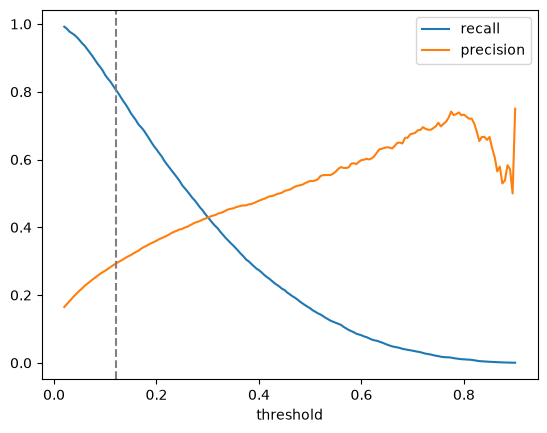

In [7]:
p_va = predict_proba(Xva, w, b)
ths = np.linspace(0.02, 0.9, 177)
rec = np.array([recall_score(y_va, p_va >= t) for t in ths])
prec = np.array([precision_score(y_va, p_va >= t, zero_division=0) for t in ths])

thr = ths[rec >= 0.80].max()                       # catch 80% of diabetics
thr_high = ths[prec >= 0.50].min() if (prec >= 0.50).any() else 0.5
thr_high = max(thr_high, thr * 1.5)
print("elevated at >=", round(thr, 3), "| high at >=", round(thr_high, 3))

plt.plot(ths, rec, label="recall"); plt.plot(ths, prec, label="precision")
plt.axvline(thr, ls="--", color="gray"); plt.xlabel("threshold"); plt.legend()
plt.savefig("../reports/threshold.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
Xte = scale(X_te)
p_te = predict_proba(Xte, w, b)
pred = p_te >= thr
print("Test AUC:", round(roc_auc_score(y_te, p_te), 3))
print("Always-predict-healthy accuracy:", round(1 - y_te.mean(), 3))
print(confusion_matrix(y_te, pred))
print(classification_report(y_te, pred))

Test AUC: 0.817
Always-predict-healthy accuracy: 0.861
[[29841 13826]
 [ 1376  5693]]
              precision    recall  f1-score   support

         0.0       0.96      0.68      0.80     43667
         1.0       0.29      0.81      0.43      7069

    accuracy                           0.70     50736
   macro avg       0.62      0.74      0.61     50736
weighted avg       0.86      0.70      0.75     50736



GenHlth                 1.81
BMI                     1.58
Age                     1.52
HighBP                  1.45
HighChol                1.34
Sex                     1.11
HeartDiseaseorAttack    1.07
DiffWalk                1.06
Stroke                  1.04
Smoker                  1.00
Veggies                 0.98
PhysActivity            0.98
MentHlth                0.98
Fruits                  0.96
PhysHlth                0.94
HvyAlcoholConsump       0.83
dtype: float64


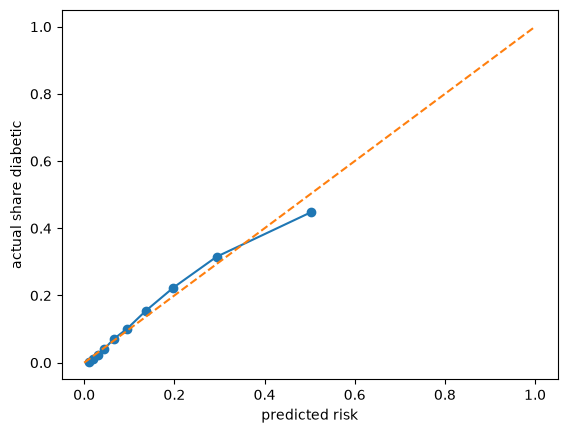

,missed,all diabetics
HighBP,0.30,0.75
HighChol,0.34,0.67
BMI,27.66,31.78
Smoker,0.44,0.52
Stroke,0.02,0.09
HeartDiseaseorAttack,0.05,0.22
PhysActivity,0.80,0.63
Fruits,0.65,0.60
Veggies,0.81,0.75
HvyAlcoholConsump,0.06,0.02


In [9]:
# Odds ratio per 1 standard deviation increase
print(pd.Series(np.exp(w), index=FEATURES).sort_values(ascending=False).round(2))

# Calibration
from sklearn.calibration import calibration_curve
frac, mean_p = calibration_curve(y_te, p_te, n_bins=10, strategy="quantile")
plt.plot(mean_p, frac, "o-"); plt.plot([0, 1], [0, 1], "--")
plt.xlabel("predicted risk"); plt.ylabel("actual share diabetic")
plt.savefig("../reports/calibration.png", dpi=150, bbox_inches="tight"); plt.show()

# Error analysis: who does the model miss?
fn = (y_te == 1) & (p_te < thr)
cmp = pd.DataFrame(X_te[fn], columns=FEATURES).mean().rename("missed")
cmp = pd.concat([cmp, pd.DataFrame(X_te[y_te == 1], columns=FEATURES).mean().rename("all diabetics")], axis=1)
cmp.round(2)

In [10]:
os.makedirs("../models", exist_ok=True)
np.savez("../models/model.npz", w=w, b=b, mu=mu, sd=sd)
json.dump({"features": FEATURES, "thr": float(thr), "thr_high": float(thr_high),
           "test_auc": float(roc_auc_score(y_te, p_te)),
           "test_recall": float(recall_score(y_te, pred)),
           "test_precision": float(precision_score(y_te, pred))},
          open("../models/meta.json", "w"), indent=2)